# HW3 — Optimization algorithms for logistic regression

We implement logistic regression from scratch and compare full-batch Gradient Descent (GD), Stochastic Gradient Descent (SGD), and Adam on the `bioresponse.csv` dataset.

## Student information

- **Name:** Oleg Yurchik
- **Group:** J4133
- **Assignment:** HW3



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

DATA = Path('../HW1/bioresponse.csv')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
X = df.drop(columns='Activity').to_numpy(dtype=np.float64)
y = df['Activity'].to_numpy(dtype=np.float64)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.20, random_state=42, stratify=y_train_full)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)
pd.DataFrame({'split': ['train', 'validation', 'test'], 'rows': [len(y_train), len(y_val), len(y_test)]}).set_index('split')

,rows
split,
train,2250
validation,563
test,938


## 1. Logistic regression from scratch

The implementation uses binary cross-entropy and a numerically stable sigmoid function. The data is split into train, validation, and test sets; scaling statistics are fitted on the training split only.

In [2]:
def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1.0 / (1.0 + np.exp(-z))

def loss_and_gradient(w, b, X, y):
    p = sigmoid(X @ w + b)
    loss = log_loss(y, p, labels=[0, 1])
    error = p - y
    return loss, (X.T @ error) / len(y), error.mean()

def predict_proba(w, b, X):
    return sigmoid(X @ w + b)

def evaluate(w, b, X, y):
    p = predict_proba(w, b, X)
    return {'accuracy': accuracy_score(y, p >= 0.5), 'log_loss': log_loss(y, p, labels=[0, 1])}

## 2. Full-batch GD, SGD, and Adam

Each optimizer returns the parameter values and the training loss after every epoch. The same initialization and number of epochs are used for a fair comparison.

In [3]:
def train_gd(X, y, learning_rate=0.05, epochs=300, seed=42):
    rng = np.random.default_rng(seed); w = rng.normal(0, 0.01, X.shape[1]); b = 0.0; losses = []
    for _ in range(epochs):
        loss, dw, db = loss_and_gradient(w, b, X, y)
        w -= learning_rate * dw; b -= learning_rate * db; losses.append(loss)
    return w, b, np.array(losses)

def train_sgd(X, y, learning_rate=0.01, epochs=300, batch_size=64, seed=42):
    rng = np.random.default_rng(seed); w = rng.normal(0, 0.01, X.shape[1]); b = 0.0; losses = []
    for _ in range(epochs):
        order = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            _, dw, db = loss_and_gradient(w, b, X[idx], y[idx])
            w -= learning_rate * dw; b -= learning_rate * db
        losses.append(loss_and_gradient(w, b, X, y)[0])
    return w, b, np.array(losses)

def train_adam(X, y, learning_rate=0.01, epochs=300, beta1=0.9, beta2=0.999, eps=1e-8, seed=42):
    rng = np.random.default_rng(seed); w = rng.normal(0, 0.01, X.shape[1]); b = 0.0
    mw = np.zeros_like(w); vw = np.zeros_like(w); mb = 0.0; vb = 0.0; losses = []
    for step in range(1, epochs + 1):
        loss, dw, db = loss_and_gradient(w, b, X, y)
        mw = beta1 * mw + (1 - beta1) * dw; vw = beta2 * vw + (1 - beta2) * dw**2
        mb = beta1 * mb + (1 - beta1) * db; vb = beta2 * vb + (1 - beta2) * db**2
        mw_hat = mw / (1 - beta1**step); vw_hat = vw / (1 - beta2**step)
        mb_hat = mb / (1 - beta1**step); vb_hat = vb / (1 - beta2**step)
        w -= learning_rate * mw_hat / (np.sqrt(vw_hat) + eps)
        b -= learning_rate * mb_hat / (np.sqrt(vb_hat) + eps)
        losses.append(loss)
    return w, b, np.array(losses)

In [4]:
optimizers = {
    'GD': lambda: train_gd(X_train, y_train, learning_rate=0.05),
    'SGD': lambda: train_sgd(X_train, y_train, learning_rate=0.01),
    'Adam': lambda: train_adam(X_train, y_train, learning_rate=0.01),
}
trained = {name: fn() for name, fn in optimizers.items()}
comparison = pd.DataFrame({name: evaluate(w, b, X_test, y_test) for name, (w, b, _) in trained.items()}).T
comparison.round(4)

,accuracy,log_loss
GD,0.7580,0.5858
SGD,0.7420,0.8185
Adam,0.7228,1.0866


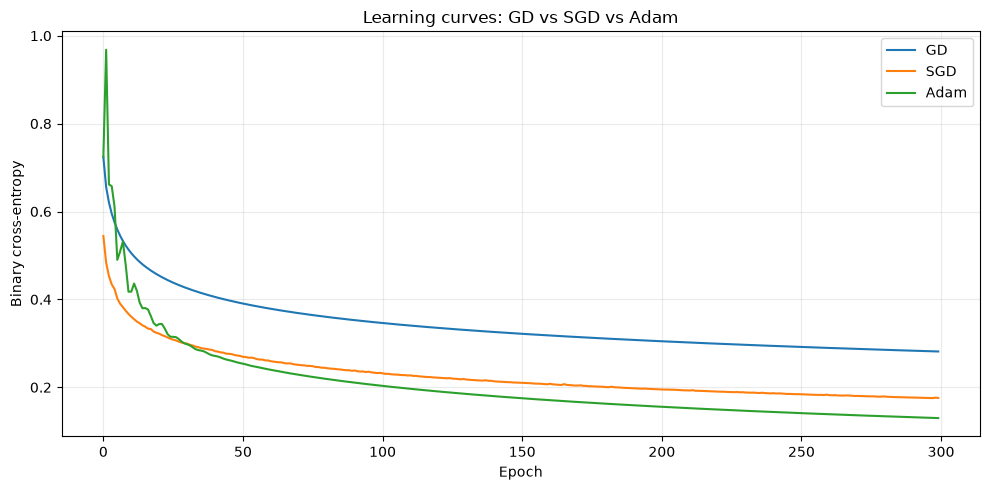

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, (_, _, losses) in trained.items(): ax.plot(losses, label=name)
ax.set(xlabel='Epoch', ylabel='Binary cross-entropy', title='Learning curves: GD vs SGD vs Adam')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()
fig.savefig(OUT / 'optimizer_learning_curves.png', dpi=160, bbox_inches='tight')

## 3. Learning-rate experiment

We train all three methods with five learning rates. The final test accuracy and loss are collected in a table, while the curves show convergence behaviour.

In [6]:
learning_rates = [0.0001, 0.001, 0.01, 0.05, 0.1]
rate_rows = []
rate_curves = {}
for method in ['GD', 'SGD', 'Adam']:
    rate_curves[method] = {}
    for rate in learning_rates:
        trainer = {'GD': train_gd, 'SGD': train_sgd, 'Adam': train_adam}[method]
        w, b, losses = trainer(X_train, y_train, learning_rate=rate, epochs=120, seed=42)
        validation_score = evaluate(w, b, X_val, y_val)
        test_score = evaluate(w, b, X_test, y_test)
        rate_rows.append({'method': method, 'learning_rate': rate, 'validation_accuracy': validation_score['accuracy'], 'validation_log_loss': validation_score['log_loss'], 'test_accuracy': test_score['accuracy'], 'test_log_loss': test_score['log_loss']})
        rate_curves[method][rate] = losses
rate_results = pd.DataFrame(rate_rows)
rate_results.round(4)

,method,learning_rate,validation_accuracy,validation_log_loss,test_accuracy,test_log_loss
0,GD,0.0001,0.5329,0.6954,0.5554,0.6995
1,GD,0.0010,0.6838,0.6157,0.6588,0.6262
2,GD,0.0100,0.7336,0.5385,0.7505,0.5383
3,GD,0.0500,0.7460,0.5549,0.7601,0.5413
4,GD,0.1000,0.7425,0.5989,0.7569,0.5739
5,SGD,0.0001,0.7300,0.5638,0.7260,0.5712
6,SGD,0.0010,0.7513,0.5442,0.7559,0.5328
7,SGD,0.0100,0.7531,0.7309,0.7569,0.6879
8,SGD,0.0500,0.7425,1.1694,0.7303,0.9824
9,SGD,0.1000,0.7300,1.5180,0.7196,1.2149


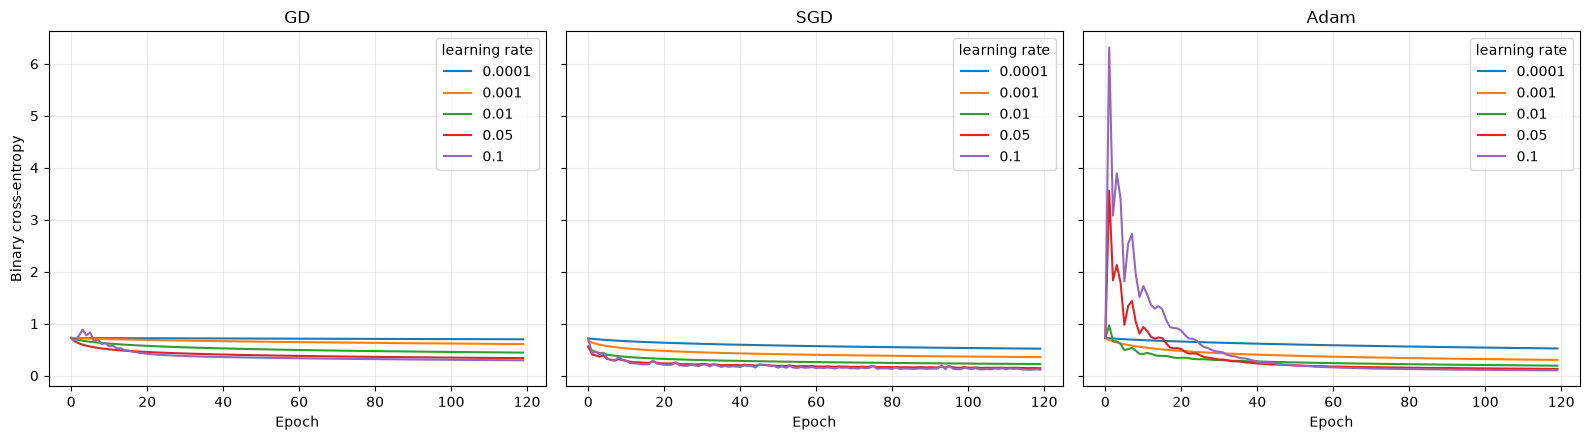

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, method in zip(axes, ['GD', 'SGD', 'Adam']):
    for rate, losses in rate_curves[method].items(): ax.plot(losses, label=str(rate))
    ax.set(title=method, xlabel='Epoch'); ax.grid(alpha=.25); ax.legend(title='learning rate')
axes[0].set_ylabel('Binary cross-entropy')
plt.tight_layout(); plt.show()
fig.savefig(OUT / 'learning_rate_curves.png', dpi=160, bbox_inches='tight')
rate_results.to_csv(OUT / 'learning_rate_results.csv', index=False)

In [8]:
best_by_method = rate_results.loc[rate_results.groupby('method')['validation_log_loss'].idxmin()].sort_values('method')
majority_class = int(pd.Series(y_train).mode().iloc[0])
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
summary = best_by_method[['method', 'learning_rate', 'validation_accuracy', 'validation_log_loss', 'test_accuracy', 'test_log_loss']].copy()
summary.loc[len(summary)] = ['Majority baseline', np.nan, np.nan, np.nan, baseline_accuracy, np.nan]
summary.round(4)

,method,learning_rate,validation_accuracy,validation_log_loss,test_accuracy,test_log_loss
10,Adam,0.0001,0.7034,0.5858,0.7292,0.5855
2,GD,0.0100,0.7336,0.5385,0.7505,0.5383
6,SGD,0.0010,0.7513,0.5442,0.7559,0.5328
3,Majority baseline,NaN,NaN,NaN,0.5426,NaN


## Conclusion

GD uses the exact gradient of the full training set and produces the smoothest learning curve. SGD updates parameters using mini-batches, so its curve is noisier, but each update is cheaper and can help the optimization escape unhelpful regions. Adam combines momentum with adaptive per-parameter step sizes and usually reaches a good solution faster.

The learning-rate experiment confirms that the learning rate is critical: a value that is too small converges slowly, while a value that is too large can oscillate or diverge. The final setting should therefore be selected using a validation protocol rather than the test set. Accuracy and log-loss may rank models differently because log-loss also evaluates the confidence and calibration of predicted probabilities. Overall, the experiments demonstrate how optimization strategy and learning-rate choice affect both convergence speed and final model quality.
